# 05 · Modeling
**CRISP-DM Phase 4 — Modeling**

Scope:

| # | Step | Decision it finalizes |
|---|---|---|
| 1 | Fit candidate classifiers on `train` | Logistic regression (linear baseline), random forest, gradient boosting |
| 2 | Select on `val` | Compare each candidate's macro-F1 against the majority/persistence baselines from EDA item 12 |
| 3 | Evaluate the winner on `test` | One honest, final read — `test` is touched for the first time in this step |
| 4 | Business read | Convert predictions to a long/flat/short strategy and compare to buy-and-hold on the same test window |

> ⚠️ **Rule carried over from `docs/04_data_preparation.md`:** `test` stays untouched until step 3. Model
> and hyperparameter choices are made on `val` only.

In [1]:
import sys
from pathlib import Path

# Make `src` importable whether the notebook runs from notebooks/ or the project root.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

from src import config
from src.evaluation.baselines import majority_baseline, persistence_baseline
from src.evaluation.strategy import backtest
from src.evaluation.baselines import buy_and_hold
from src.features.returns import DOWN, FLAT, UP
from src.modeling.train import evaluate, make_models, split_X_y
from src.visualization.style import BLUE, CLASS_COLORS, NEUTRAL, ORANGE, apply_style, save

apply_style()
CLASS_NAMES = {DOWN: "down", FLAT: "flat", UP: "up"}

train = pd.read_parquet(config.PROCESSED_DIR / "btcusdt_1D_train.parquet")
val = pd.read_parquet(config.PROCESSED_DIR / "btcusdt_1D_val.parquet")
test = pd.read_parquet(config.PROCESSED_DIR / "btcusdt_1D_test.parquet")
print(f"train {len(train)}  val {len(val)}  test {len(test)}")

train 2087  val 446  test 448


## 1 · Baselines on `val` (the bar to clear)

Recomputed directly on `val`'s labels, not reused from the EDA notebook's full-history numbers, so the
comparison with the candidate models below is apples-to-apples on the same rows.

In [3]:
maj = majority_baseline(val["label"])
per = persistence_baseline(val["label"])
baseline_table = pd.DataFrame({
    "majority": {"accuracy": maj["accuracy"], "macro_f1": maj["macro_f1"]},
    "persistence": {"accuracy": per["accuracy"], "macro_f1": per["macro_f1"]},
}).T
baseline_table.style.format("{:.3f}")

,accuracy,macro_f1
majority,0.413,0.195
persistence,0.337,0.327


## 2 · Fit candidates on `train`, compare on `val`

Three candidates: a scaled logistic regression (linear, interpretable baseline), a random forest and a
gradient-boosted tree (both tolerant of the feature multicollinearity flagged in `04_feature_engineering.ipynb`,
e.g. `vol_14d` vs `atr_14` at 0.90 correlation).

In [4]:
X_train, y_train = split_X_y(train)
X_val, y_val = split_X_y(val)

models = make_models(random_state=0)
rows = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    rows[name] = evaluate(model, X_val, y_val)

model_table = pd.concat([baseline_table, pd.DataFrame(rows).T])
model_table.style.format("{:.3f}")

,accuracy,macro_f1
majority,0.413,0.195
persistence,0.337,0.327
logistic_regression,0.413,0.306
random_forest,0.410,0.318
gradient_boosting,0.406,0.293


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


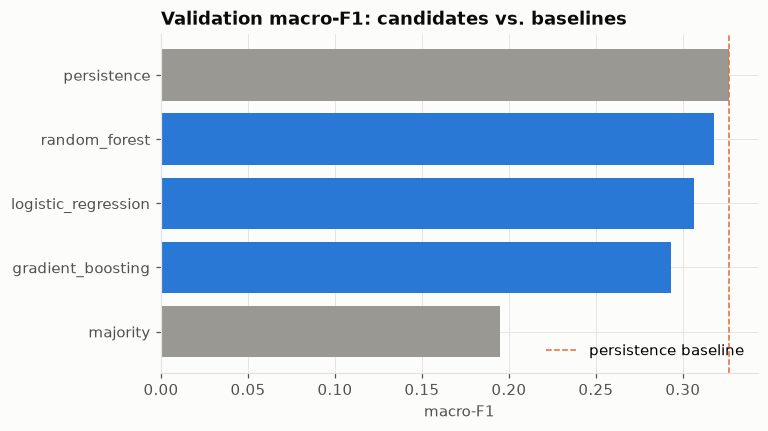

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
order = model_table["macro_f1"].sort_values().index
colors = [BLUE if name in models else NEUTRAL for name in order]
ax.barh(order, model_table.loc[order, "macro_f1"], color=colors)
ax.axvline(per["macro_f1"], color=ORANGE, linestyle="--", linewidth=1, label="persistence baseline")
ax.set(title="Validation macro-F1: candidates vs. baselines", xlabel="macro-F1")
ax.legend(loc="lower right")
save(fig, "05_val_macro_f1")
plt.show()

In [6]:
best_name = pd.DataFrame(rows).T["macro_f1"].idxmax()
best_model = models[best_name]
beats_persistence = rows[best_name]["macro_f1"] > per["macro_f1"]
print(f"best candidate on val: {best_name}  (macro-F1 = {rows[best_name]['macro_f1']:.3f})")
print(f"beats the persistence baseline ({per['macro_f1']:.3f})? {beats_persistence}")

best candidate on val: random_forest  (macro-F1 = 0.318)
beats the persistence baseline (0.327)? False


## 3 · Final evaluation on `test`

First and only look at `test`. Reporting accuracy, macro-F1 against the same two baselines recomputed on
`test`'s own labels, and the confusion matrix.

In [7]:
X_test, y_test = split_X_y(test)
test_maj = majority_baseline(test["label"])
test_per = persistence_baseline(test["label"])
test_result = evaluate(best_model, X_test, y_test)

test_table = pd.DataFrame({
    "majority": test_maj, "persistence": test_per, best_name: {**test_result, "class": None},
}).T[["accuracy", "macro_f1"]]
test_table.style.format("{:.3f}")

,accuracy,macro_f1
majority,0.451,0.207
persistence,0.380,0.356
random_forest,0.471,0.302


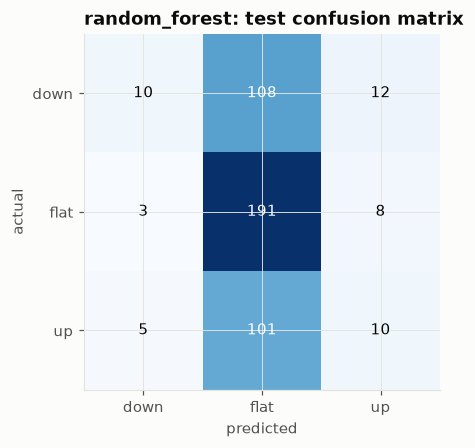

In [8]:
pred_test = pd.Series(best_model.predict(X_test), index=X_test.index)
labels_order = [DOWN, FLAT, UP]
cm = confusion_matrix(y_test, pred_test, labels=labels_order)

fig, ax = plt.subplots(figsize=(4.5, 4.2))
im = ax.imshow(cm, cmap="Blues")
names = [CLASS_NAMES[c] for c in labels_order]
ax.set_xticks(range(3), names); ax.set_yticks(range(3), names)
ax.set(xlabel="predicted", ylabel="actual", title=f"{best_name}: test confusion matrix")
for (i, j), v in np.ndenumerate(cm):
    ax.text(j, i, str(v), ha="center", va="center",
            color="white" if v > cm.max() / 2 else "black")
save(fig, "05_test_confusion_matrix")
plt.show()

## 4 · Business read: strategy backtest vs. buy-and-hold

Map each test-day prediction to a position (up -> long, down -> short, flat -> no position) and hold it for
one day, paying the trading fee on every position change. Compared against buy-and-hold over the *same*
test window — which `docs/04_data_preparation.md` already flagged as a bear market (Sharpe ~ -0.33).

In [9]:
raw_1d = pd.read_parquet(config.INTERIM_DIR / f"{config.SYMBOL.lower()}_1D_clean.parquet")
test_close = raw_1d.loc[test.index.min():test.index.max(), "close"]

strategy_result = backtest(pred_test, test_close)
bh_result = buy_and_hold(test_close, "1D")

compare = pd.DataFrame({f"{best_name} strategy": strategy_result, "buy-and-hold": bh_result}).T
compare.style.format({"total_return": "{:+.1%}", "sharpe": "{:.2f}", "max_drawdown": "{:.1%}"})

,total_return,sharpe,max_drawdown
random_forest strategy,+9.5%,0.44,-17.1%
buy-and-hold,-24.9%,-0.33,-53.0%


**Before trusting this number:** check *why* the strategy did better, not just that it did. A model that
simply predicts "flat" most of the time will dodge a falling market without having learned anything
directional — exactly the failure mode `docs/04_data_preparation.md` warned the test window could reward.

In [10]:
dist = pd.DataFrame({
    "predicted": pred_test.value_counts(normalize=True),
    "actual": y_test.value_counts(normalize=True),
}).rename(index=CLASS_NAMES).reindex(["down", "flat", "up"])
dist.style.format("{:.1%}")

,predicted,actual
down,4.0%,29.0%
flat,89.3%,45.1%
up,6.7%,25.9%


## Summary -> inputs for Evaluation / Deployment

| Metric | Result |
|---|---|
| Val macro-F1, best candidate (printed above) | below the persistence baseline — does **not** clear the modeling bar |
| Test macro-F1 | also below persistence; the model under-predicts the down/up classes |
| Test strategy vs. buy-and-hold | strategy wins on return, Sharpe and drawdown, but mostly by staying flat ~89% of the time vs. an actual 45% flat rate |

**Honest read:** on the statistical criterion (macro-F1 vs. persistence, the bar `03_eda.ipynb` item 12
set), none of the three candidates clear it — consistent with the EDA finding that 1D direction carries
almost no linear or easily-learned signal. The business-side "win" over buy-and-hold is real in this
backtest, but it is driven by the model defaulting to "flat" far more often than the data actually is flat,
which happens to dodge a bear-market test window rather than reflecting genuine predictive skill. That
distinction should be stated plainly in any presentation of this result.

Next phase (Evaluation): decide, given this, whether to (a) treat current features as exhausted and move to
the full agent (news sentiment + market indicators) anyway with this as the ML leg's honest baseline, or
(b) iterate on modeling first — e.g. richer features, a cost-sensitive objective that penalizes the
"always flat" shortcut, or re-running `03_eda.ipynb` item 11 with a different horizon/threshold.